In [1]:
# Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Load the dataset
df = pd.read_csv("S&P 500 Stock Prices 2014-2017.csv")

In [3]:
# Check the data size
df.shape

(497472, 7)

In [4]:
# Examine the first five records
df.head()

,symbol,date,open,high,low,close,volume
0,AAL,1/2/2014,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,1/2/2014,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,1/2/2014,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,1/2/2014,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,1/2/2014,70.1100,70.2300,69.4800,69.8900,1148391


In [5]:
# Check the column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 497472 entries, 0 to 497471
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   symbol  497472 non-null  object 
 1   date    497472 non-null  object 
 2   open    497461 non-null  float64
 3   high    497464 non-null  float64
 4   low     497464 non-null  float64
 5   close   497472 non-null  float64
 6   volume  497472 non-null  int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 26.6+ MB


In [6]:
# Check how many stock symbols we have
df['symbol'].nunique()

505

In [7]:
# Display the stock symbols
df['symbol'].unique()

array(['AAL', 'AAPL', 'AAP', 'ABBV', 'ABC', 'ABT', 'ACN', 'ADBE', 'ADI',
       'ADM', 'ADP', 'ADSK', 'ADS', 'AEE', 'AEP', 'AES', 'AET', 'AFL',
       'AGN', 'AIG', 'AIV', 'AIZ', 'AJG', 'AKAM', 'ALB', 'ALGN', 'ALK',
       'ALLE', 'ALL', 'ALXN', 'AMAT', 'AMD', 'AME', 'AMGN', 'AMG', 'AMP',
       'AMT', 'AMZN', 'ANDV', 'ANSS', 'ANTM', 'AON', 'AOS', 'APA', 'APC',
       'APD', 'APH', 'ARE', 'ARNC', 'ATVI', 'AVB', 'AVGO', 'AVY', 'AWK',
       'AXP', 'AYI', 'AZO', 'A', 'BAC', 'BAX', 'BA', 'BBT', 'BBY', 'BDX',
       'BEN', 'BF.B', 'BIIB', 'BK', 'BLK', 'BLL', 'BMY', 'BRK.B', 'BSX',
       'BWA', 'BXP', 'CAG', 'CAH', 'CAT', 'CA', 'CBG', 'CBOE', 'CBS',
       'CB', 'CCI', 'CCL', 'CDNS', 'CELG', 'CERN', 'CF', 'CHD', 'CHK',
       'CHRW', 'CHTR', 'CINF', 'CI', 'CLX', 'CL', 'CMA', 'CMCSA', 'CME',
       'CMG', 'CMI', 'CMS', 'CNC', 'CNP', 'COF', 'COG', 'COL', 'COO',
       'COP', 'COST', 'COTY', 'CPB', 'CRM', 'CSCO', 'CSX', 'CTAS', 'CTL',
       'CTSH', 'CTXS', 'CVS', 'CVX', 'CXO', 'C', 'DAL', 'D

In [8]:
# Check the date range
df['date'].min(), df['date'].max()

('1/10/2014', '9/9/2016')

In [9]:
# Convert the date column from object to actual date format
df['date'] = pd.to_datetime(df['date'], format='%m/%d/%Y')

In [10]:
# Check the date range again
df['date'].min(), df['date'].max()

(Timestamp('2014-01-02 00:00:00'), Timestamp('2017-12-29 00:00:00'))

In [11]:
# Check for missing values
df.isnull().sum()

symbol     0
date       0
open      11
high       8
low        8
close      0
volume     0
dtype: int64

In [12]:
# Check for duplicates
df.duplicated().sum()

0

In [13]:
# Check for duplicate stock-date combinations
df.duplicated(subset=['symbol', 'date']).sum()

0

In [14]:
# Check zero-volume observations
(df['volume'] == 0).sum()

4

In [15]:
# Identify the affected records
df[df['volume'] == 0]

,symbol,date,open,high,low,close,volume
249223,DHR,2016-01-12,NaN,NaN,NaN,88.55,0
249438,O,2016-01-12,NaN,NaN,NaN,52.43,0
278801,UA,2016-04-07,NaN,NaN,NaN,41.56,0
308365,FTV,2016-07-01,NaN,NaN,NaN,49.54,0


In [16]:
# Check the number of trading dates for each stock
df.groupby('symbol')['date'].nunique().describe()

count     505.000000
mean      985.093069
std       118.785643
min        18.000000
25%      1007.000000
50%      1007.000000
75%      1007.000000
max      1007.000000
Name: date, dtype: float64

In [17]:
# Identify the stocks with incomplete histories
stock_date_counts = df.groupby('symbol')['date'].nunique()

stock_date_counts[stock_date_counts < 1007].sort_values()

symbol
APTV      18
DWDP      83
BHF      117
BHGE     126
DXC      189
HLT      250
EVHC     271
FTV      378
UA       438
WLTW     502
CSRA     535
HPE      555
HPQ      555
PYPL     629
KHC      629
WRK      636
QRVO     755
CFG      824
SYF      862
INFO     891
NAVI     934
GOOG     949
O        995
DHR      995
ES       997
ICE     1006
Name: date, dtype: int64

In [18]:
# Investigate unusual price values
df[['open', 'high', 'low', 'close', 'volume']].describe()

,open,high,low,close,volume
count,497461.000000,497464.000000,497464.000000,497472.000000,4.974720e+05
mean,86.352275,87.132562,85.552467,86.369082,4.253611e+06
std,101.471228,102.312062,100.570957,101.472407,8.232139e+06
min,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,41.690000,42.090000,41.280000,41.703750,1.080166e+06
50%,64.970000,65.560000,64.353700,64.980000,2.084896e+06
75%,98.410000,99.230000,97.580000,98.420000,4.271928e+06
max,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08


In [19]:
# Which stocks and dates have these highest values
df.loc[df['close'].idxmax()]

symbol                   PCLN
date      2017-08-08 00:00:00
open                   2044.0
high                  2067.99
low                   2035.11
close                  2049.0
volume                 830572
Name: 446926, dtype: object

In [20]:
# Investigate the highest trading volume
df.loc[df['volume'].idxmax()]

symbol                     VZ
date      2014-02-24 00:00:00
open                    47.02
high                     47.2
low                     46.23
close                   46.23
volume              618237630
Name: 17361, dtype: object

In [21]:
# Check how many records have unusually high closing prices above 1,000
df[df['close'] > 1000][['symbol', 'date', 'close']]

,symbol,date,close
344,PCLN,2014-01-02,1145.44
827,PCLN,2014-01-03,1132.68
1310,PCLN,2014-01-06,1139.53
1793,PCLN,2014-01-07,1163.07
2276,PCLN,2014-01-08,1157.50
...,...,...,...
496822,PCLN,2017-12-28,1764.09
497004,AMZN,2017-12-29,1169.47
497173,GOOGL,2017-12-29,1053.40
497174,GOOG,2017-12-29,1046.40


In [22]:
# Check for impossible price relationships
invalid_prices = df[
    (df['high'] < df['low']) |
    (df['high'] < df['open']) |
    (df['high'] < df['close']) |
    (df['low'] > df['open']) |
    (df['low'] > df['close'])
]

invalid_prices.shape

(12, 7)

In [23]:
# Let's inspect them to understand what is wrong
invalid_prices

,symbol,date,open,high,low,close,volume
45501,AOS,2014-05-19,23.890,23.5950,23.850,24.4450,1944854
45548,CHD,2014-05-19,18.770,33.9525,33.695,33.8950,1078888
48774,SPG,2014-05-28,176.230,176.6000,174.500,165.4200,1383759
59618,CHK,2014-06-30,30.430,31.1000,30.370,29.3900,8132836
60252,IP,2014-07-01,50.850,51.0700,50.570,50.0900,5624981
79814,O,2014-08-27,44.675,44.7000,44.660,44.5272,185518
103984,DHR,2014-11-06,78.470,81.3050,80.490,81.2600,1614419
104196,O,2014-11-06,44.740,47.5700,46.730,46.8600,1803132
269985,BBY,2016-03-14,33.550,33.7500,33.080,32.7200,6037794
291756,WRK,2016-05-13,42.450,42.8900,41.820,38.3900,2153541


In [24]:
# Find out which type of inconsistency occurs most often
print("High below Open:", (df['high'] < df['open']).sum())
print("High below Close:", (df['high'] < df['close']).sum())
print("Low above Open:", (df['low'] > df['open']).sum())
print("Low above Close:", (df['low'] > df['close']).sum())

High below Open: 1
High below Close: 1
Low above Open: 3
Low above Close: 8


In [25]:
# Check whether any stock has a negative price or volume
print("Negative prices:", (df[['open', 'high', 'low', 'close']] < 0).sum())
print("Negative volumes:", (df['volume'] < 0).sum())

Negative prices: open     0
high     0
low      0
close    0
dtype: int64
Negative volumes: 0


In [26]:
# Sort the dataset
df = df.sort_values(['symbol', 'date']).reset_index(drop=True)

In [27]:
# Create Year, Month and Quarter columns
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter

In [28]:
# Daily price change
df['daily_price_change'] = df.groupby('symbol')['close'].diff()

In [29]:
# Daily percentage return
df['daily_percentage_return'] = (
    df.groupby('symbol')['close']
    .pct_change() * 100
)

In [30]:
# Daily trading range
df['daily_percentage_return'] = (
    df.groupby('symbol')['close']
    .pct_change() * 100
)

In [31]:
# Moving average
df['ma_20'] = (
    df.groupby('symbol')['close']
    .transform(lambda x: x.rolling(window=20).mean())
)

df['ma_50'] = (
    df.groupby('symbol')['close']
    .transform(lambda x: x.rolling(window=50).mean())
)

In [32]:
df['daily_trading_range'] = df['high'] - df['low']

In [33]:
df[['symbol', 'date', 'close', 'year', 'month', 'quarter',
    'daily_price_change', 'daily_percentage_return',
    'daily_trading_range', 'ma_20', 'ma_50']].head(25)

,symbol,date,close,year,month,quarter,daily_price_change,daily_percentage_return,daily_trading_range,ma_20,ma_50
0,A,2014-01-02,56.21,2014,1,1,NaN,NaN,0.9500,NaN,NaN
1,A,2014-01-03,56.92,2014,1,1,0.71,1.263120,1.0850,NaN,NaN
2,A,2014-01-06,56.64,2014,1,1,-0.28,-0.491918,1.1400,NaN,NaN
3,A,2014-01-07,57.45,2014,1,1,0.81,1.430085,0.7000,NaN,NaN
4,A,2014-01-08,58.39,2014,1,1,0.94,1.636205,1.3700,NaN,NaN
5,A,2014-01-09,58.41,2014,1,1,0.02,0.034252,0.8100,NaN,NaN
6,A,2014-01-10,58.93,2014,1,1,0.52,0.890259,0.8700,NaN,NaN
7,A,2014-01-13,58.93,2014,1,1,0.00,0.000000,0.5000,NaN,NaN
8,A,2014-01-14,59.88,2014,1,1,0.95,1.612082,0.9300,NaN,NaN
9,A,2014-01-15,60.34,2014,1,1,0.46,0.768203,0.7800,NaN,NaN


In [34]:
df[df['symbol'] == 'A'][['date', 'close', 'ma_20', 'ma_50']].iloc[45:52]

,date,close,ma_20,ma_50
45,2014-03-10,58.15,57.5170,NaN
46,2014-03-11,56.86,57.4095,NaN
47,2014-03-12,57.06,57.2760,NaN
48,2014-03-13,55.85,57.0740,NaN
49,2014-03-14,55.44,56.8420,57.9758
50,2014-03-17,55.80,56.8695,57.9676
51,2014-03-18,56.79,56.9515,57.9650


In [35]:
# Which stocks recorded the highest closing prices?
highest_closing_prices = (
    df.groupby('symbol')['close']
    .max()
    .sort_values(ascending=False)
)

highest_closing_prices.head(10)

symbol
PCLN     2049.00
AMZN     1195.83
GOOGL    1085.09
GOOG     1077.14
AZO       815.98
CMG       757.77
MTD       689.11
REGN      592.40
BLK       518.86
EQIX      492.98
Name: close, dtype: float64

In [36]:
# Which stocks recorded the highest and lowest percentage returns?
average_returns = (
    df.groupby('symbol')['daily_percentage_return']
    .mean()
)

print("Top 10 stocks by average daily return:")
display(average_returns.sort_values(ascending=False).head(10))

print("Bottom 10 stocks by average daily return:")
display(average_returns.sort_values().head(10))

Top 10 stocks by average daily return:


symbol
NVDA    0.276020
DXC     0.185460
AVGO    0.177969
EA      0.169227
AMD     0.168442
NFLX    0.165104
ALGN    0.154462
SWKS    0.148829
CNC     0.144794
ATVI    0.141883
Name: daily_percentage_return, dtype: float64

Bottom 10 stocks by average daily return:


symbol
BHGE    -0.396924
APTV    -0.257371
UA      -0.217750
EVHC    -0.210633
BHF     -0.138816
RRC     -0.113508
DISCA   -0.099924
DISCK   -0.098441
MAT     -0.089325
CHK     -0.086530
Name: daily_percentage_return, dtype: float64

In [37]:
# Top 10 stocks by average daily return
average_returns.sort_values(ascending=False).head(10)

symbol
NVDA    0.276020
DXC     0.185460
AVGO    0.177969
EA      0.169227
AMD     0.168442
NFLX    0.165104
ALGN    0.154462
SWKS    0.148829
CNC     0.144794
ATVI    0.141883
Name: daily_percentage_return, dtype: float64

In [38]:
# Which stocks experienced the greatest price volatility?
stock_volatility = (
    df.groupby('symbol')['daily_percentage_return']
    .std()
    .sort_values(ascending=False)
)

stock_volatility.head(10)

symbol
CHK     4.551547
AMD     3.910169
LNT     3.700607
FCX     3.698899
BHGE    3.661471
WMB     3.234744
MRO     3.216357
EVHC    2.955314
RRC     2.907283
INCY    2.856040
Name: daily_percentage_return, dtype: float64

In [39]:
# Which stocks recorded the highest trading volumes?
average_volume = (
    df.groupby('symbol')['volume']
    .mean()
    .sort_values(ascending=False)
)

average_volume.head(10)

symbol
BAC     8.936290e+07
AAPL    4.516957e+07
GE      4.144394e+07
AMD     3.328951e+07
F       3.291430e+07
MSFT    3.071261e+07
FB      2.922782e+07
MU      2.796281e+07
CHK     2.788540e+07
INTC    2.716114e+07
Name: volume, dtype: float64

In [40]:
# How did selected stocks perform between 2014 and 2017?
selected_stocks = ['AAPL', 'AMZN', 'GOOGL', 'MSFT', 'NVDA']

yearly_performance = (
    df[df['symbol'].isin(selected_stocks)]
    .groupby(['symbol', 'year'])['close']
    .mean()
    .unstack()
)

yearly_performance

year,2014,2015,2016,2017
symbol,,,,
AAPL,92.264531,120.039861,104.604008,150.585080
AMZN,332.550976,478.138194,699.523135,968.151394
GOOGL,568.122203,619.988234,763.214206,939.773386
MSFT,42.453343,46.713810,55.259306,71.984024
NVDA,18.546808,23.717817,53.761190,149.783705


In [41]:
# How did stock prices vary across months and years?
monthly_prices = (
    df.groupby('month')['close']
    .mean()
)

monthly_prices

month
1     80.761525
2     81.982437
3     84.703273
4     84.867746
5     85.926009
6     87.068109
7     87.630218
8     88.069635
9     86.981584
10    87.445862
11    89.851097
12    90.381482
Name: close, dtype: float64

In [42]:
yearly_prices = (
    df.groupby('year')['close']
    .mean()
)

yearly_prices

year
2014    76.969836
2015    84.134718
2016    85.253095
2017    98.800312
Name: close, dtype: float64

In [43]:
# Which stocks experienced the largest daily price changes?
largest_daily_changes = (
    df.assign(
        absolute_price_change=df['daily_price_change'].abs()
    )
    .sort_values(
        'absolute_price_change',
        ascending=False
    )
    [['symbol', 'date', 'daily_price_change',
      'absolute_price_change']]
    .head(10)
)

largest_daily_changes

,symbol,date,daily_price_change,absolute_price_change
354647,PCLN,2017-11-07,-257.28,257.28
354301,PCLN,2016-06-24,-158.06,158.06
354584,PCLN,2017-08-09,-142.20,142.20
354144,PCLN,2015-11-09,-138.75,138.75
39229,AMZN,2017-10-27,128.52,128.52
354211,PCLN,2016-02-17,124.88,124.88
354265,PCLN,2016-05-04,-101.60,101.60
353889,PCLN,2014-11-04,-100.82,100.82
202234,GOOGL,2015-07-17,97.84,97.84
354396,PCLN,2016-11-08,97.80,97.80


In [44]:
# How does trading activity differ across selected stock symbols?
selected_stocks = ['AAPL', 'AMZN', 'GOOGL', 'MSFT', 'NVDA']

selected_volume = (
    df[df['symbol'].isin(selected_stocks)]
    .groupby('symbol')['volume']
    .mean()
    .sort_values(ascending=False)
)

selected_volume

symbol
AAPL     4.516957e+07
MSFT     3.071261e+07
NVDA     1.076129e+07
AMZN     3.880125e+06
GOOGL    2.107184e+06
Name: volume, dtype: float64

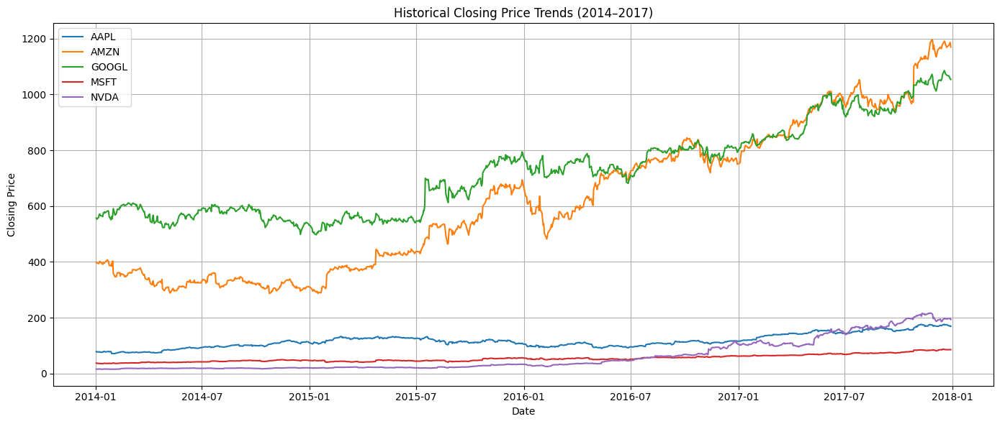

In [45]:
# Compare closing price trends
selected_stocks = ['AAPL', 'AMZN', 'GOOGL', 'MSFT', 'NVDA']

plt.figure(figsize=(14, 6))

for stock in selected_stocks:
    stock_data = df[df['symbol'] == stock]
    plt.plot(stock_data['date'], stock_data['close'], label=stock)

plt.title('Historical Closing Price Trends (2014–2017)')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

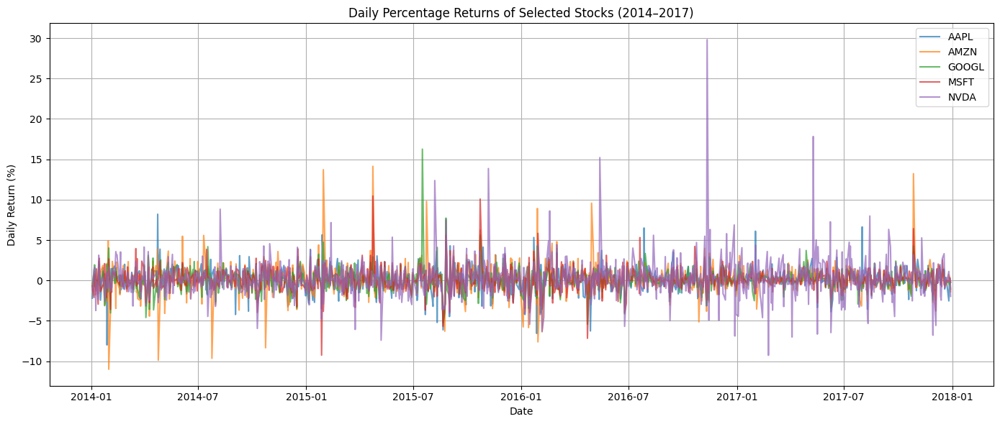

In [46]:
# Compare daily percentage returns
plt.figure(figsize=(14, 6))

for stock in selected_stocks:
    stock_data = df[df['symbol'] == stock]
    plt.plot(
        stock_data['date'],
        stock_data['daily_percentage_return'],
        label=stock,
        alpha=0.7
    )

plt.title('Daily Percentage Returns of Selected Stocks (2014–2017)')
plt.xlabel('Date')
plt.ylabel('Daily Return (%)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

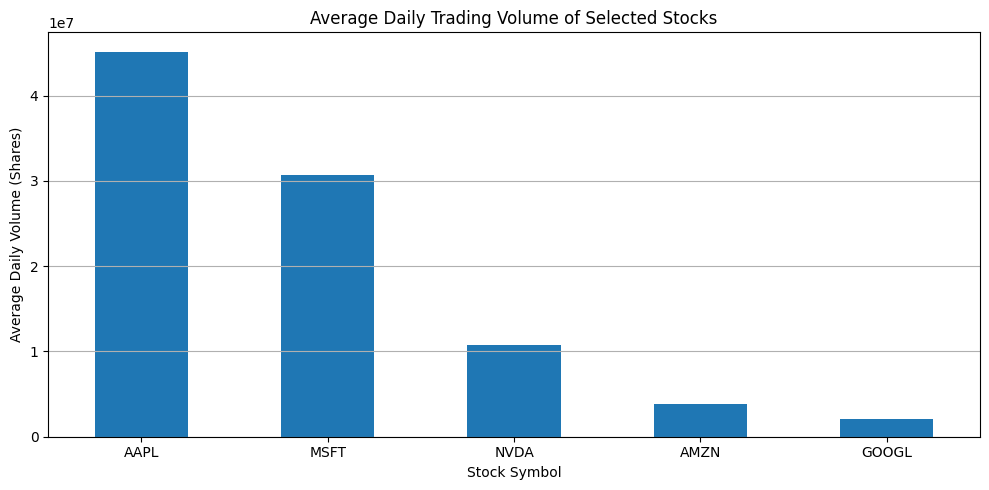

In [47]:
# Compare trading volumes
plt.figure(figsize=(10, 5))

selected_volume.plot(kind='bar')

plt.title('Average Daily Trading Volume of Selected Stocks')
plt.xlabel('Stock Symbol')
plt.ylabel('Average Daily Volume (Shares)')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [48]:
# Compare price volatility
selected_volatility = (
    df[df['symbol'].isin(selected_stocks)]
    .groupby('symbol')['daily_percentage_return']
    .std()
    .sort_values(ascending=False)
)

selected_volatility

symbol
NVDA     2.373885
AMZN     1.864574
AAPL     1.430893
GOOGL    1.382401
MSFT     1.369469
Name: daily_percentage_return, dtype: float64

In [49]:
# Compare highest and lowest closing prices
price_extremes = (
    df[df['symbol'].isin(selected_stocks)]
    .groupby('symbol')['close']
    .agg(['min', 'max'])
    .rename(columns={
        'min': 'lowest_closing_price',
        'max': 'highest_closing_price'
    })
)

price_extremes

,lowest_closing_price,highest_closing_price
symbol,,
AAPL,71.3974,176.42
AMZN,286.9500,1195.83
GOOGL,497.0600,1085.09
MSFT,34.9800,86.85
NVDA,15.3600,216.96


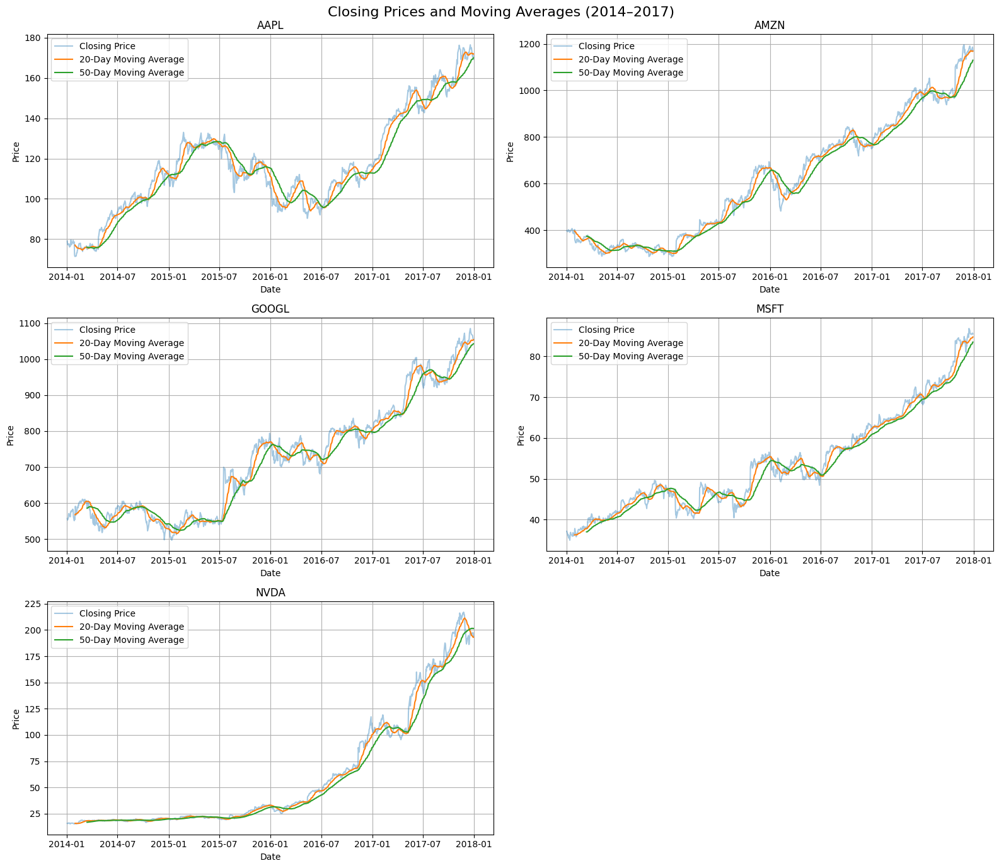

In [50]:
# Compare moving average trends
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()

for i, stock in enumerate(selected_stocks):
    stock_data = df[df['symbol'] == stock]

    axes[i].plot(
        stock_data['date'],
        stock_data['close'],
        label='Closing Price',
        alpha=0.4
    )

    axes[i].plot(
        stock_data['date'],
        stock_data['ma_20'],
        label='20-Day Moving Average'
    )

    axes[i].plot(
        stock_data['date'],
        stock_data['ma_50'],
        label='50-Day Moving Average'
    )

    axes[i].set_title(stock)
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price')
    axes[i].legend()
    axes[i].grid(True)

fig.delaxes(axes[5])

plt.suptitle(
    'Closing Prices and Moving Averages (2014–2017)',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [51]:
# Calculate the cumulative percentage return for the five stocks from their first available closing price to their last available closing price
cumulative_returns = (
    df[df['symbol'].isin(selected_stocks)]
    .groupby('symbol')
    .apply(
        lambda x: (
            (x['close'].iloc[-1] - x['close'].iloc[0])
            / x['close'].iloc[0]
        ) * 100,
        include_groups=False
    )
    .sort_values(ascending=False)
)

cumulative_returns

symbol
NVDA     1120.050441
AMZN      193.858834
MSFT      130.193757
AAPL      114.165037
GOOGL      89.080706
dtype: float64

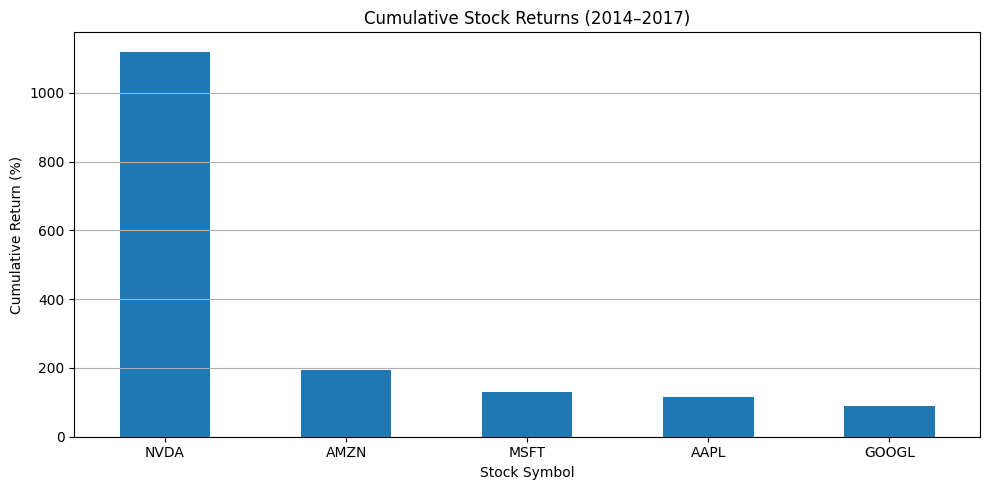

In [52]:
plt.figure(figsize=(10, 5))

cumulative_returns.plot(kind='bar')

plt.title('Cumulative Stock Returns (2014–2017)')
plt.xlabel('Stock Symbol')
plt.ylabel('Cumulative Return (%)')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [53]:
# Calculate the dashboard summary metrics
# Dashboard summary metrics

total_symbols = df['symbol'].nunique()
total_records = len(df)

start_date = df['date'].min()
end_date = df['date'].max()

average_closing_prices = (
    df[df['symbol'].isin(selected_stocks)]
    .groupby('symbol')['close']
    .mean()
    .round(2)
)

print("MARKET OVERVIEW")
print("---------------------------")
print("Total Stock Symbols:", total_symbols)
print("Total Trading Records:", f"{total_records:,}")
print("Date Range:", start_date.date(), "to", end_date.date())

print("\nAverage Closing Prices:")
display(average_closing_prices)

MARKET OVERVIEW
---------------------------
Total Stock Symbols: 505
Total Trading Records: 497,472
Date Range: 2014-01-02 to 2017-12-29

Average Closing Prices:


symbol
AAPL     116.84
AMZN     619.24
GOOGL    722.56
MSFT      54.08
NVDA      61.36
Name: close, dtype: float64

In [54]:
# Number of trading records for each stock

symbol_distribution = (
    df['symbol']
    .value_counts()
    .sort_values(ascending=False)
)

print("Number of stock symbols:", len(symbol_distribution))
display(symbol_distribution.head(10))

Number of stock symbols: 505


symbol
A       1007
SNI     1007
ADSK    1007
AEE     1007
AEP     1007
AES     1007
AET     1007
AFL     1007
AGN     1007
AIG     1007
Name: count, dtype: int64

In [55]:
import plotly.express as px

fig = px.bar(
    x=symbol_distribution.index,
    y=symbol_distribution.values,
    labels={
        'x': 'Stock Symbol',
        'y': 'Number of Trading Records'
    },
    title='Trading Record Distribution Across Stock Symbols'
)

fig.update_layout(
    xaxis_tickangle=-90,
    height=600,
    template='plotly_white'
)

fig.show()

In [56]:
# General market overview chart
# Average closing price across all stocks by year

market_trend = (
    df.groupby('year')['close']
    .mean()
    .reset_index()
)

fig = px.line(
    market_trend,
    x='year',
    y='close',
    markers=True,
    title='Average Closing Price Across All Stocks (2014–2017)',
    labels={
        'year': 'Year',
        'close': 'Average Closing Price'
    }
)

fig.update_layout(template='plotly_white')
fig.show()

In [57]:
# KPI cards
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=1,
    cols=3,
    specs=[[{'type': 'indicator'},
            {'type': 'indicator'},
            {'type': 'indicator'}]],
    subplot_titles=(
        'Total Stock Symbols',
        'Total Trading Records',
        'Available Trading Period'
    )
)

fig.add_trace(
    go.Indicator(
        mode='number',
        value=total_symbols,
        number={'valueformat': ',d'}
    ),
    row=1, col=1
)

fig.add_trace(
    go.Indicator(
        mode='number',
        value=total_records,
        number={'valueformat': ',d'}
    ),
    row=1, col=2
)

fig.add_trace(
    go.Indicator(
        mode='number',
        value=(end_date - start_date).days,
        number={'suffix': ' days'}
    ),
    row=1, col=3
)

fig.update_layout(
    title='Market Overview – Key Metrics',
    template='plotly_white',
    height=300
)

fig.show()

In [58]:
# Page 1: Market Overview
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=3,
    cols=2,
    specs=[
        [{'type': 'indicator'}, {'type': 'indicator'}],
        [{'type': 'bar', 'rowspan': 2}, {'type': 'xy'}],
        [None, {'type': 'bar'}]
    ],
    subplot_titles=(
        'Total Stock Symbols',
        'Total Trading Records',
        'Trading Records by Stock Symbol',
        'Average Closing Price by Year',
        'Average Closing Price of Selected Stocks'
    ),
    vertical_spacing=0.12,
    horizontal_spacing=0.12
)

# KPI cards
fig.add_trace(
    go.Indicator(mode='number', value=total_symbols),
    row=1, col=1
)

fig.add_trace(
    go.Indicator(
        mode='number',
        value=total_records,
        number={'valueformat': ',d'}
    ),
    row=1, col=2
)

# Stock symbol distribution
fig.add_trace(
    go.Bar(
        x=symbol_distribution.index,
        y=symbol_distribution.values,
        name='Trading Records'
    ),
    row=2, col=1
)

# Average closing price by year
fig.add_trace(
    go.Scatter(
        x=market_trend['year'],
        y=market_trend['close'],
        mode='lines+markers',
        name='Average Closing Price'
    ),
    row=2, col=2
)

# Average closing prices for selected stocks
fig.add_trace(
    go.Bar(
        x=average_closing_prices.index,
        y=average_closing_prices.values,
        name='Average Close'
    ),
    row=3, col=2
)

fig.update_layout(
    title='S&P 500 Stock Market – Page 1: Market Overview',
    height=1000,
    template='plotly_white',
    showlegend=False
)

fig.update_xaxes(tickangle=-90, row=2, col=1)
fig.show()

In [59]:
# install/import ipywidgets, which provides the stock selector and date controls inside Jupyter
%pip install ipywidgets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [60]:
import ipywidgets as widgets
from IPython.display import display

In [61]:
%pip install "jupyterlab-widgets>=1.0.0,<3.0.0"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [62]:
# Stock symbol selector
stock_selector = widgets.Dropdown(
    options=sorted(df['symbol'].unique()),
    value='AAPL',
    description='Stock:',
    style={'description_width': 'initial'}
)

# Date filters
start_date_picker = widgets.DatePicker(
    description='Start Date:',
    value=df['date'].min().date()
)

end_date_picker = widgets.DatePicker(
    description='End Date:',
    value=df['date'].max().date()
)

display(stock_selector, start_date_picker, end_date_picker)

Dropdown(description='Stock:', index=3, options=('A', 'AAL', 'AAP', 'AAPL', 'ABBV', 'ABC', 'ABT', 'ACN', 'ADBE…

DatePicker(value=datetime.date(2014, 1, 2), description='Start Date:')

DatePicker(value=datetime.date(2017, 12, 29), description='End Date:')

In [63]:
# Filter the selected stock
def filter_stock_data(symbol, start_date, end_date):
    stock_data = df[
        (df['symbol'] == symbol) &
        (df['date'] >= pd.Timestamp(start_date)) &
        (df['date'] <= pd.Timestamp(end_date))
    ].copy()

    return stock_data


stock_data = filter_stock_data(
    stock_selector.value,
    start_date_picker.value,
    end_date_picker.value
)

print("Selected Stock:", stock_selector.value)
print("Records Found:", len(stock_data))
print("Date Range:", stock_data['date'].min(), "to", stock_data['date'].max())

Selected Stock: AAPL
Records Found: 1007
Date Range: 2014-01-02 00:00:00 to 2017-12-29 00:00:00


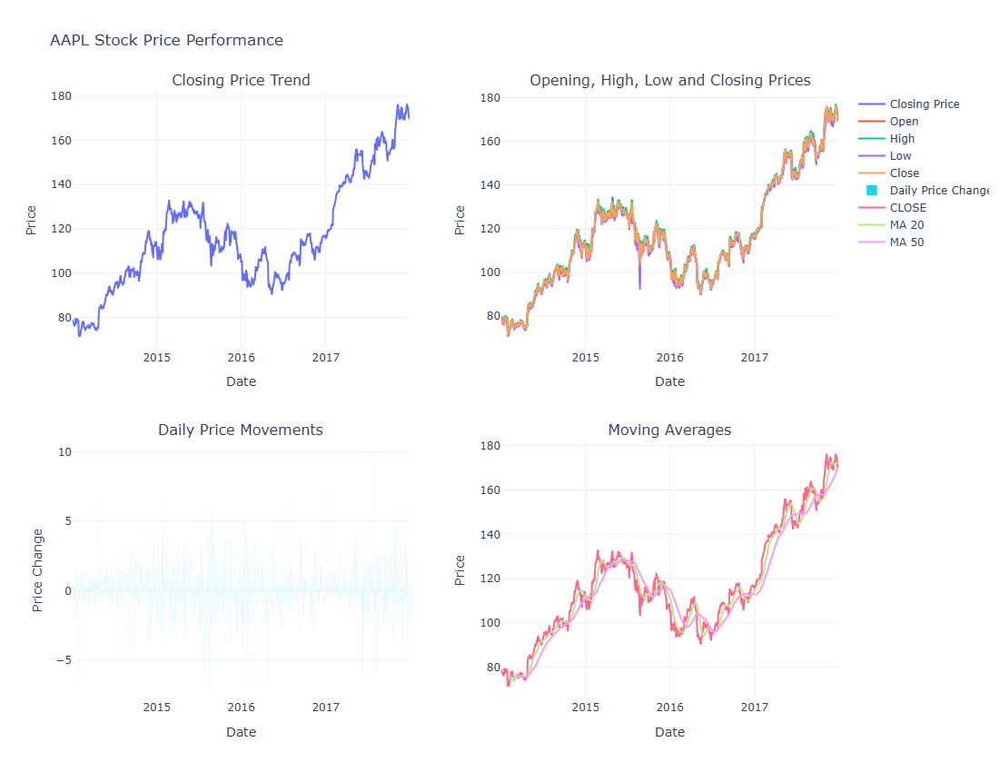

In [64]:
# Stock performance dashboard
def update_stock_performance(symbol, start_date, end_date):

    stock_data = filter_stock_data(symbol, start_date, end_date)

    if stock_data.empty:
        print("No records found for the selected date range.")
        return

    fig = make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            'Closing Price Trend',
            'Opening, High, Low and Closing Prices',
            'Daily Price Movements',
            'Moving Averages'
        ),
        vertical_spacing=0.15,
        horizontal_spacing=0.12
    )

    # 1. Closing price trend
    fig.add_trace(
        go.Scatter(
            x=stock_data['date'],
            y=stock_data['close'],
            mode='lines',
            name='Closing Price'
        ),
        row=1, col=1
    )

    # 2. Open, High, Low and Close comparison
    for column in ['open', 'high', 'low', 'close']:
        fig.add_trace(
            go.Scatter(
                x=stock_data['date'],
                y=stock_data[column],
                mode='lines',
                name=column.capitalize()
            ),
            row=1, col=2
        )

    # 3. Daily price movements
    fig.add_trace(
        go.Bar(
            x=stock_data['date'],
            y=stock_data['daily_price_change'],
            name='Daily Price Change'
        ),
        row=2, col=1
    )

    # 4. Moving averages
    for column in ['close', 'ma_20', 'ma_50']:
        fig.add_trace(
            go.Scatter(
                x=stock_data['date'],
                y=stock_data[column],
                mode='lines',
                name=column.replace('_', ' ').upper()
            ),
            row=2, col=2
        )

    fig.update_layout(
        title=f'{symbol} Stock Price Performance',
        height=850,
        template='plotly_white',
        hovermode='x unified'
    )

    fig.update_xaxes(title_text='Date')
    fig.update_yaxes(title_text='Price', row=1, col=1)
    fig.update_yaxes(title_text='Price', row=1, col=2)
    fig.update_yaxes(title_text='Price Change', row=2, col=1)
    fig.update_yaxes(title_text='Price', row=2, col=2)

    fig.show()


update_stock_performance(
    stock_selector.value,
    start_date_picker.value,
    end_date_picker.value
)

In [65]:
# Connect the controls to the dashboard

dashboard_output = widgets.interactive_output(
    update_stock_performance,
    {
        'symbol': stock_selector,
        'start_date': start_date_picker,
        'end_date': end_date_picker
    }
)

display(dashboard_output)

Output()

In [66]:
display(stock_selector)
display(start_date_picker)
display(end_date_picker)

Dropdown(description='Stock:', index=3, options=('A', 'AAL', 'AAP', 'AAPL', 'ABBV', 'ABC', 'ABT', 'ACN', 'ADBE…

DatePicker(value=datetime.date(2014, 1, 2), description='Start Date:')

DatePicker(value=datetime.date(2017, 12, 29), description='End Date:')

In [67]:
# Filter data for the five selected stocks
returns_data = df[
    df['symbol'].isin(selected_stocks)
].copy()

# Calculate average daily returns
average_daily_returns = (
    returns_data.groupby('symbol')['daily_percentage_return']
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE DAILY RETURNS (%)")
display(average_daily_returns.round(4))

AVERAGE DAILY RETURNS (%)


symbol
NVDA     0.2760
AMZN     0.1244
MSFT     0.0922
AAPL     0.0860
GOOGL    0.0728
Name: daily_percentage_return, dtype: float64

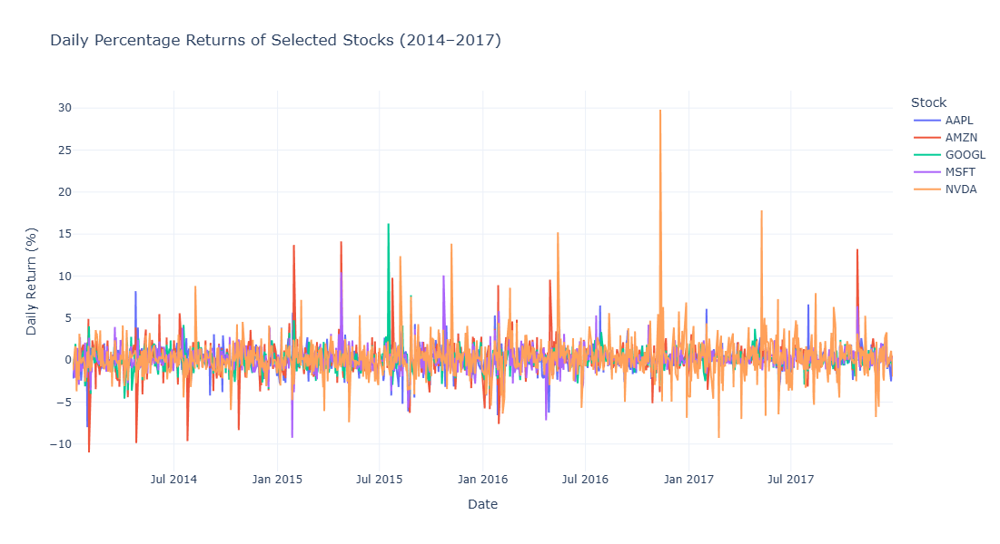

In [68]:
fig = px.line(
    returns_data,
    x='date',
    y='daily_percentage_return',
    color='symbol',
    title='Daily Percentage Returns of Selected Stocks (2014–2017)',
    labels={
        'date': 'Date',
        'daily_percentage_return': 'Daily Return (%)',
        'symbol': 'Stock'
    }
)

fig.update_layout(
    template='plotly_white',
    hovermode='x unified',
    height=600
)

fig.show()

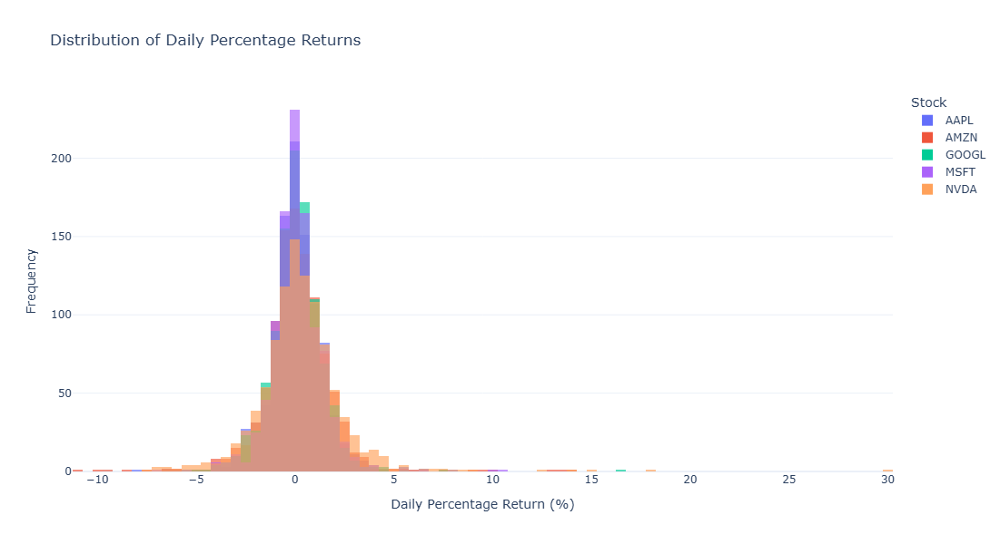

In [69]:
fig = px.histogram(
    returns_data,
    x='daily_percentage_return',
    color='symbol',
    barmode='overlay',
    opacity=0.65,
    nbins=100,
    title='Distribution of Daily Percentage Returns',
    labels={
        'daily_percentage_return': 'Daily Return (%)',
        'symbol': 'Stock'
    }
)

fig.update_layout(
    template='plotly_white',
    height=600,
    xaxis_title='Daily Percentage Return (%)',
    yaxis_title='Frequency'
)

fig.show()

In [70]:
# Calculate historical volatility for selected stocks
historical_volatility = (
    returns_data.groupby('symbol')['daily_percentage_return']
    .std()
    .sort_values(ascending=False)
)

print("HISTORICAL VOLATILITY (%)")
display(historical_volatility.round(4))

HISTORICAL VOLATILITY (%)


symbol
NVDA     2.3739
AMZN     1.8646
AAPL     1.4309
GOOGL    1.3824
MSFT     1.3695
Name: daily_percentage_return, dtype: float64

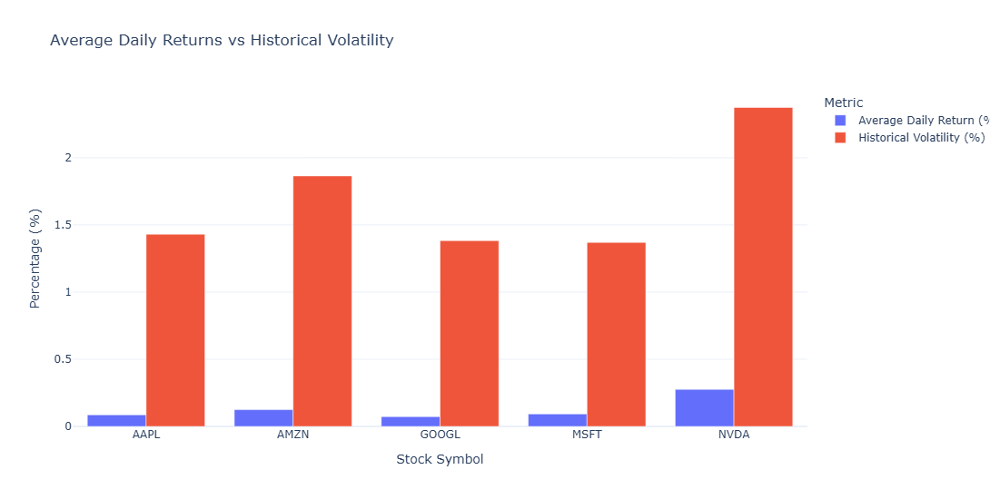

In [72]:
volatility_comparison = pd.DataFrame({
    'Average Daily Return (%)': average_daily_returns,
    'Historical Volatility (%)': historical_volatility
}).reset_index()

fig = px.bar(
    volatility_comparison,
    x='symbol',
    y=['Average Daily Return (%)', 'Historical Volatility (%)'],
    barmode='group',
    title='Average Daily Returns vs Historical Volatility',
    labels={
        'symbol': 'Stock Symbol',
        'value': 'Percentage (%)',
        'variable': 'Metric'
    }
)

fig.update_layout(
    template='plotly_white',
    height=550
)

fig.show()

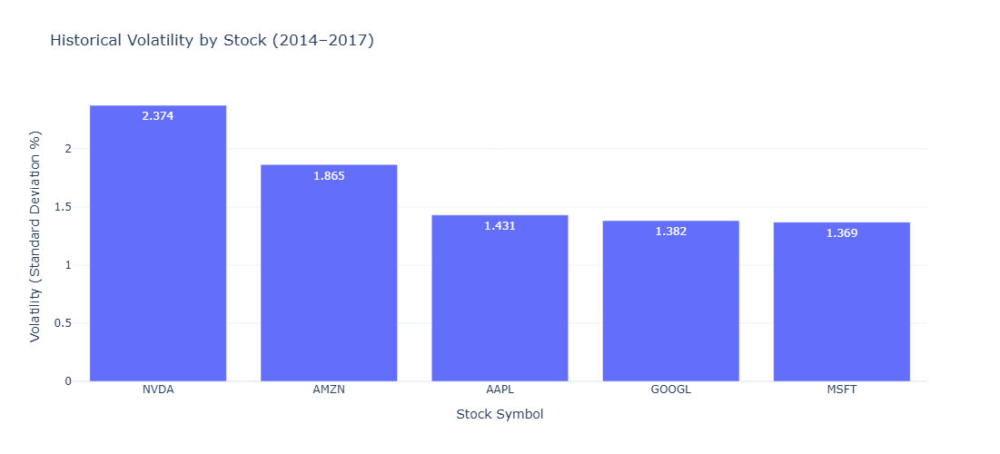

In [73]:
# Historical volatility comparison
fig = px.bar(
    historical_volatility.reset_index(),
    x='symbol',
    y='daily_percentage_return',
    title='Historical Volatility by Stock (2014–2017)',
    labels={
        'symbol': 'Stock Symbol',
        'daily_percentage_return': 'Volatility (Standard Deviation %)'
    },
    text_auto='.3f'
)

fig.update_layout(
    template='plotly_white',
    height=500
)

fig.show()

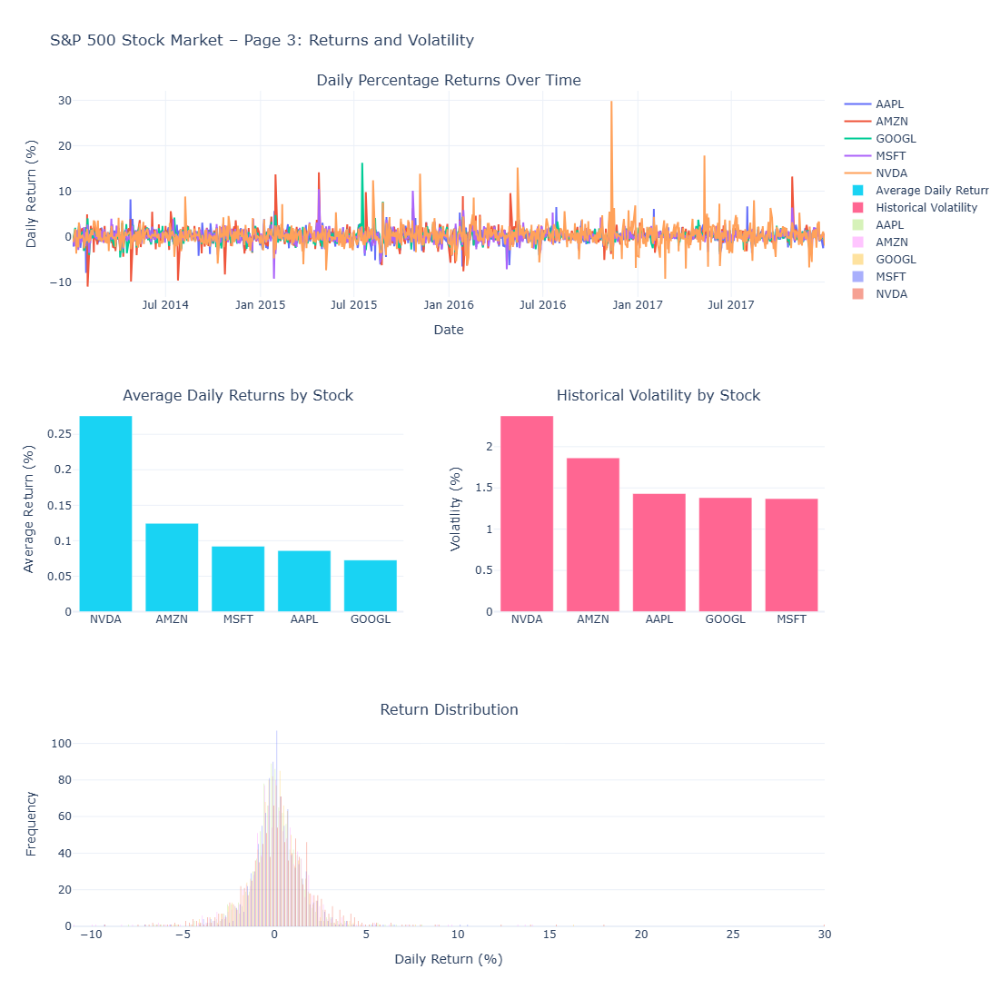

In [74]:
# Returns and volatility
fig = make_subplots(
    rows=3, cols=2,
    specs=[
        [{'type': 'xy', 'colspan': 2}, None],
        [{'type': 'bar'}, {'type': 'bar'}],
        [{'type': 'xy', 'colspan': 2}, None]
    ],
    subplot_titles=(
        'Daily Percentage Returns Over Time',
        'Average Daily Returns by Stock',
        'Historical Volatility by Stock',
        'Return Distribution'
    ),
    vertical_spacing=0.13,
    horizontal_spacing=0.12
)

# 1. Daily percentage returns
for stock in selected_stocks:
    stock_data = returns_data[returns_data['symbol'] == stock]

    fig.add_trace(
        go.Scatter(
            x=stock_data['date'],
            y=stock_data['daily_percentage_return'],
            mode='lines',
            name=stock
        ),
        row=1, col=1
    )

# 2. Average daily returns
fig.add_trace(
    go.Bar(
        x=average_daily_returns.index,
        y=average_daily_returns.values,
        name='Average Daily Return'
    ),
    row=2, col=1
)

# 3. Historical volatility
fig.add_trace(
    go.Bar(
        x=historical_volatility.index,
        y=historical_volatility.values,
        name='Historical Volatility'
    ),
    row=2, col=2
)

# 4. Return distribution
for stock in selected_stocks:
    stock_data = returns_data[
        returns_data['symbol'] == stock
    ]

    fig.add_trace(
        go.Histogram(
            x=stock_data['daily_percentage_return'],
            name=stock,
            opacity=0.55
        ),
        row=3, col=1
    )

fig.update_layout(
    title='S&P 500 Stock Market – Page 3: Returns and Volatility',
    template='plotly_white',
    height=1100,
    barmode='group',
    hovermode='closest'
)

fig.update_xaxes(title_text='Date', row=1, col=1)
fig.update_yaxes(title_text='Daily Return (%)', row=1, col=1)
fig.update_yaxes(title_text='Average Return (%)', row=2, col=1)
fig.update_yaxes(title_text='Volatility (%)', row=2, col=2)
fig.update_xaxes(title_text='Daily Return (%)', row=3, col=1)
fig.update_yaxes(title_text='Frequency', row=3, col=1)

fig.show()

In [75]:
# Prepare trading volume data
volume_data = df[
    df['symbol'].isin(selected_stocks)
].copy()

# Calculate average trading volume
average_trading_volume = (
    volume_data.groupby('symbol')['volume']
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE DAILY TRADING VOLUME")
display(average_trading_volume.round(0))

AVERAGE DAILY TRADING VOLUME


symbol
AAPL     45169571.0
MSFT     30712613.0
NVDA     10761295.0
AMZN      3880125.0
GOOGL     2107184.0
Name: volume, dtype: float64

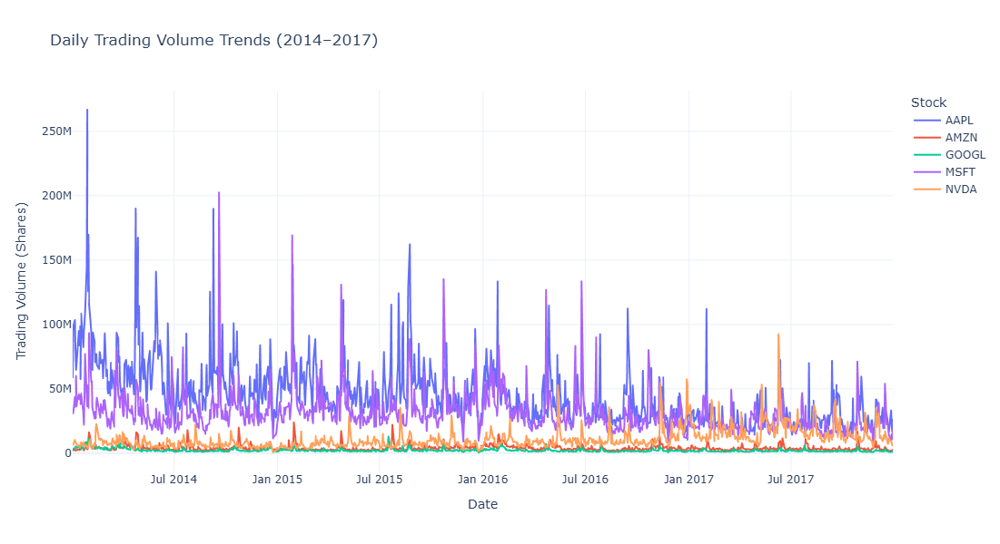

In [76]:
fig = px.line(
    volume_data,
    x='date',
    y='volume',
    color='symbol',
    title='Daily Trading Volume Trends (2014–2017)',
    labels={
        'date': 'Date',
        'volume': 'Trading Volume (Shares)',
        'symbol': 'Stock'
    }
)

fig.update_layout(
    template='plotly_white',
    height=600,
    hovermode='x unified'
)

fig.show()

In [77]:
# Highest and lowest trading volume for each stock

highest_volume = (
    volume_data.loc[
        volume_data.groupby('symbol')['volume'].idxmax(),
        ['symbol', 'date', 'volume']
    ].sort_values('volume', ascending=False)
)

lowest_volume = (
    volume_data.loc[
        volume_data.groupby('symbol')['volume'].idxmin(),
        ['symbol', 'date', 'volume']
    ].sort_values('volume')
)

print("HIGHEST TRADING VOLUME")
display(highest_volume)

print("LOWEST TRADING VOLUME")
display(lowest_volume)

HIGHEST TRADING VOLUME


,symbol,date,volume
3038,AAPL,2014-01-28,266833581
315676,MSFT,2014-09-19,202526536
340456,NVDA,2017-06-09,92323196
38537,AMZN,2015-01-30,23856060
202234,GOOGL,2015-07-17,12858136


LOWEST TRADING VOLUME


,symbol,date,volume
202346,GOOGL,2015-12-24,521141
38765,AMZN,2015-12-24,1092970
339838,NVDA,2014-12-24,1141128
316478,MSFT,2017-11-24,7425603
3752,AAPL,2016-11-25,11475922


In [78]:
highest_volume = (
    volume_data.loc[
        volume_data.groupby('symbol')['volume'].idxmax(),
        ['symbol', 'date', 'volume']
    ].sort_values('volume', ascending=False)
)

display(highest_volume)

,symbol,date,volume
3038,AAPL,2014-01-28,266833581
315676,MSFT,2014-09-19,202526536
340456,NVDA,2017-06-09,92323196
38537,AMZN,2015-01-30,23856060
202234,GOOGL,2015-07-17,12858136


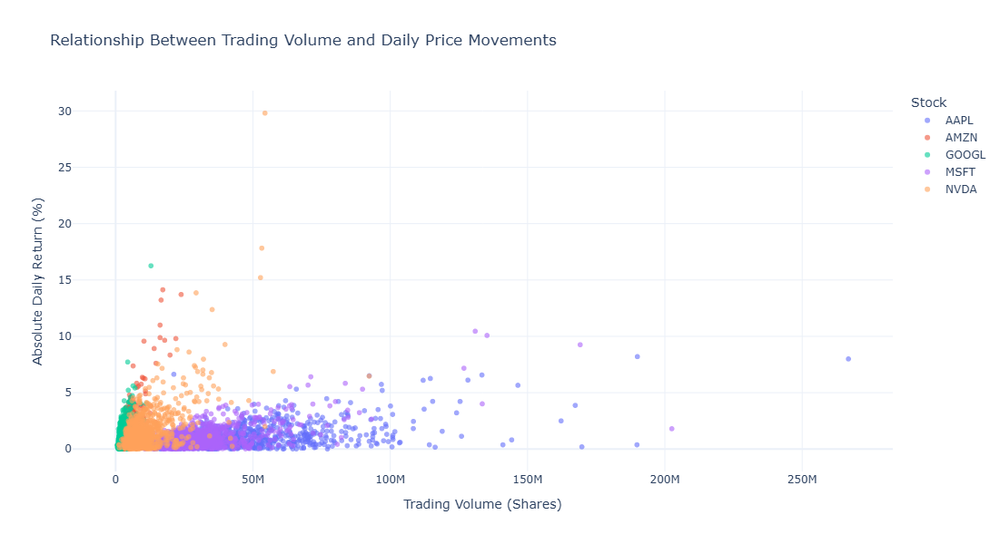

In [79]:
volume_data['absolute_daily_return'] = (
    volume_data['daily_percentage_return'].abs()
)

fig = px.scatter(
    volume_data,
    x='volume',
    y='absolute_daily_return',
    color='symbol',
    title='Relationship Between Trading Volume and Daily Price Movements',
    labels={
        'volume': 'Trading Volume (Shares)',
        'absolute_daily_return': 'Absolute Daily Return (%)',
        'symbol': 'Stock'
    },
    opacity=0.6
)

fig.update_layout(
    template='plotly_white',
    height=600
)

fig.show()

In [80]:
# Page 4 stock selector
volume_stock_selector = widgets.SelectMultiple(
    options=sorted(df['symbol'].unique()),
    value=tuple(selected_stocks),
    description='Stocks:',
    rows=6,
    style={'description_width': 'initial'}
)

# Page 4 date filters
volume_start_date = widgets.DatePicker(
    description='Start Date:',
    value=df['date'].min().date()
)

volume_end_date = widgets.DatePicker(
    description='End Date:',
    value=df['date'].max().date()
)

display(
    volume_stock_selector,
    volume_start_date,
    volume_end_date
)

SelectMultiple(description='Stocks:', index=(3, 38, 207, 322, 346), options=('A', 'AAL', 'AAP', 'AAPL', 'ABBV'…

DatePicker(value=datetime.date(2014, 1, 2), description='Start Date:')

DatePicker(value=datetime.date(2017, 12, 29), description='End Date:')

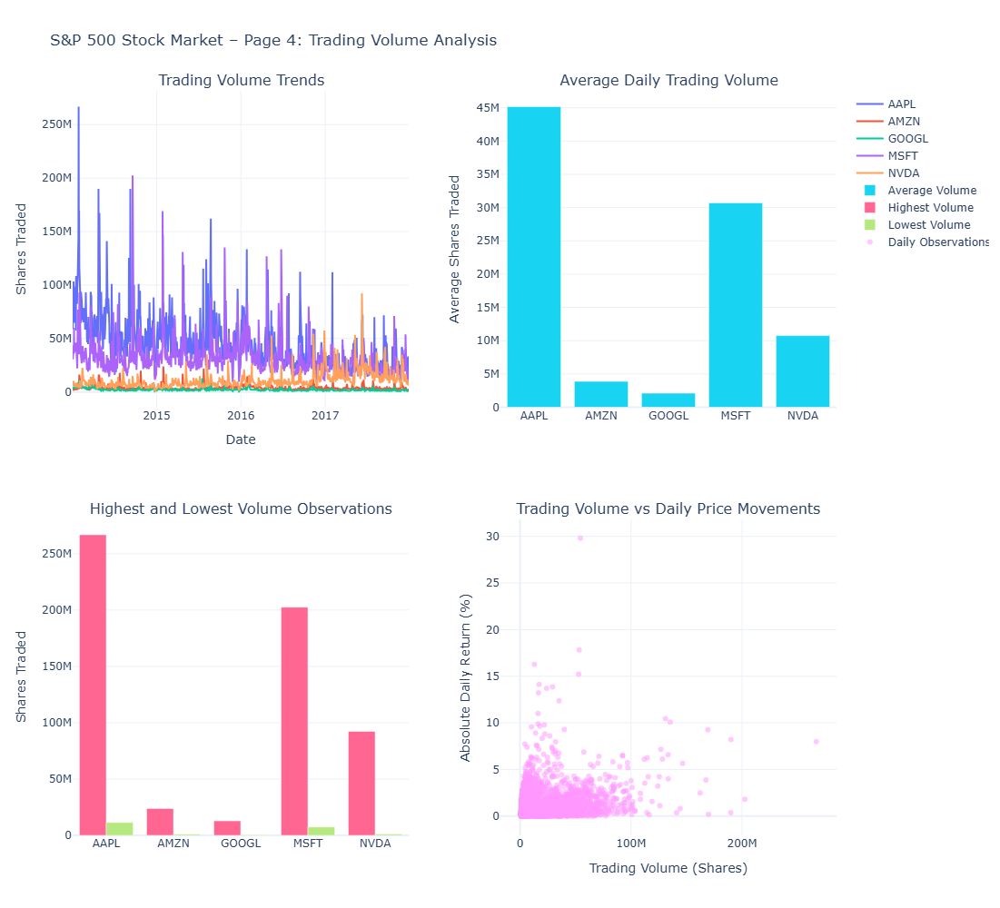

In [81]:
# Trading volume analysis
def update_volume_dashboard(stocks, start_date, end_date):

    if not stocks:
        print("Please select at least one stock.")
        return

    if start_date is None or end_date is None:
        print("Please select both dates.")
        return

    if start_date > end_date:
        print("Start date cannot be after end date.")
        return

    filtered_data = df[
        (df['symbol'].isin(stocks)) &
        (df['date'] >= pd.Timestamp(start_date)) &
        (df['date'] <= pd.Timestamp(end_date))
    ].copy()

    if filtered_data.empty:
        print("No records found for the selected filters.")
        return

    # Average trading volume
    avg_volume = (
        filtered_data.groupby('symbol')['volume']
        .mean()
        .reset_index()
    )

    # Highest and lowest volume observations
    highest = filtered_data.loc[
        filtered_data.groupby('symbol')['volume'].idxmax()
    ]

    lowest = filtered_data.loc[
        filtered_data.groupby('symbol')['volume'].idxmin()
    ]

    # Absolute daily percentage return
    filtered_data['absolute_daily_return'] = (
        filtered_data['daily_percentage_return'].abs()
    )

    fig = make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            'Trading Volume Trends',
            'Average Daily Trading Volume',
            'Highest and Lowest Volume Observations',
            'Trading Volume vs Daily Price Movements'
        ),
        vertical_spacing=0.15,
        horizontal_spacing=0.12
    )

    # 1. Trading volume trends
    for stock in stocks:
        stock_data = filtered_data[
            filtered_data['symbol'] == stock
        ]

        fig.add_trace(
            go.Scatter(
                x=stock_data['date'],
                y=stock_data['volume'],
                mode='lines',
                name=stock
            ),
            row=1, col=1
        )

    # 2. Average trading volume
    fig.add_trace(
        go.Bar(
            x=avg_volume['symbol'],
            y=avg_volume['volume'],
            name='Average Volume'
        ),
        row=1, col=2
    )

    # 3. Highest and lowest volume observations
    for label, data, color in [
        ('Highest Volume', highest, 'Highest'),
        ('Lowest Volume', lowest, 'Lowest')
    ]:
        fig.add_trace(
            go.Bar(
                x=data['symbol'],
                y=data['volume'],
                name=label,
                customdata=data['date'].dt.strftime('%Y-%m-%d'),
                hovertemplate=(
                    'Stock: %{x}<br>'
                    'Volume: %{y:,.0f}<br>'
                    'Date: %{customdata}<extra></extra>'
                )
            ),
            row=2, col=1
        )

    # 4. Trading volume vs price movements
    fig.add_trace(
        go.Scatter(
            x=filtered_data['volume'],
            y=filtered_data['absolute_daily_return'],
            mode='markers',
            marker={'size': 6, 'opacity': 0.5},
            name='Daily Observations',
            text=filtered_data['symbol'],
            hovertemplate=(
                'Stock: %{text}<br>'
                'Volume: %{x:,.0f}<br>'
                'Absolute Daily Return: %{y:.3f}%'
                '<extra></extra>'
            )
        ),
        row=2, col=2
    )

    fig.update_layout(
        title='S&P 500 Stock Market – Page 4: Trading Volume Analysis',
        template='plotly_white',
        height=1000,
        barmode='group',
        hovermode='closest'
    )

    fig.update_xaxes(title_text='Date', row=1, col=1)
    fig.update_yaxes(title_text='Shares Traded', row=1, col=1)
    fig.update_yaxes(title_text='Average Shares Traded', row=1, col=2)
    fig.update_yaxes(title_text='Shares Traded', row=2, col=1)
    fig.update_xaxes(title_text='Trading Volume (Shares)', row=2, col=2)
    fig.update_yaxes(title_text='Absolute Daily Return (%)', row=2, col=2)

    fig.show()


update_volume_dashboard(
    volume_stock_selector.value,
    volume_start_date.value,
    volume_end_date.value
)

In [82]:
volume_dashboard_output = widgets.interactive_output(
    update_volume_dashboard,
    {
        'stocks': volume_stock_selector,
        'start_date': volume_start_date,
        'end_date': volume_end_date
    }
)

display(volume_dashboard_output)

Output()

In [83]:
# Independently reload the original dataset
validation_df = pd.read_csv("S&P 500 Stock Prices 2014-2017.csv")

# Recalculate the three metrics directly from the source data
verified_symbols = validation_df['symbol'].nunique()
verified_records = len(validation_df)

verified_average_closes = (
    validation_df[validation_df['symbol'].isin(selected_stocks)]
    .groupby('symbol')['close']
    .mean()
    .round(2)
)

print("INDEPENDENT VALIDATION")
print("----------------------------")
print("Total Stock Symbols:", verified_symbols)
print("Total Trading Records:", f"{verified_records:,}")
print("\nAverage Closing Prices:")
display(verified_average_closes)

INDEPENDENT VALIDATION
----------------------------
Total Stock Symbols: 505
Total Trading Records: 497,472

Average Closing Prices:


symbol
AAPL     116.84
AMZN     619.24
GOOGL    722.56
MSFT      54.08
NVDA      61.36
Name: close, dtype: float64

In [84]:
# Independently recalculate daily percentage returns
check_returns = df.sort_values(['symbol', 'date']).copy()

check_returns['verified_return'] = (
    check_returns.groupby('symbol')['close'].pct_change() * 100
)

# Compare recalculated returns with the existing column
return_check = np.isclose(
    check_returns['daily_percentage_return'],
    check_returns['verified_return'],
    equal_nan=True
)

print("Daily return calculations match:", return_check.all())
print("Number of mismatches:", (~return_check).sum())

Daily return calculations match: True
Number of mismatches: 0


In [85]:
# Independently verify 20-day and 50-day moving averages

sample_stock = df[df['symbol'] == 'AAPL'].copy()

sample_stock['verified_ma_20'] = (
    sample_stock['close'].rolling(window=20).mean()
)

sample_stock['verified_ma_50'] = (
    sample_stock['close'].rolling(window=50).mean()
)

ma_20_match = np.isclose(
    sample_stock['ma_20'],
    sample_stock['verified_ma_20'],
    equal_nan=True
)

ma_50_match = np.isclose(
    sample_stock['ma_50'],
    sample_stock['verified_ma_50'],
    equal_nan=True
)

print("20-day moving averages match:", ma_20_match.all())
print("50-day moving averages match:", ma_50_match.all())
print("20-day mismatches:", (~ma_20_match).sum())
print("50-day mismatches:", (~ma_50_match).sum())

20-day moving averages match: True
50-day moving averages match: True
20-day mismatches: 0
50-day mismatches: 0


In [86]:
# Validate the Page 2 stock selection filter

test_symbol = 'NVDA'

filtered_test = filter_stock_data(
    test_symbol,
    start_date_picker.value,
    end_date_picker.value
)

print("Selected stock:", test_symbol)
print("Stocks returned:", filtered_test['symbol'].unique())
print("All records belong to selected stock:",
      (filtered_test['symbol'] == test_symbol).all())
print("Number of records:", len(filtered_test))

Selected stock: NVDA
Stocks returned: ['NVDA']
All records belong to selected stock: True
Number of records: 1007


In [87]:
print("Selected start date:", start_date_picker.value)
print("Selected end date:", end_date_picker.value)

print("Earliest returned date:", filtered_test['date'].min().date())
print("Latest returned date:", filtered_test['date'].max().date())

print(
    "All dates within selected range:",
    (
        (filtered_test['date'] >= pd.Timestamp(start_date_picker.value)) &
        (filtered_test['date'] <= pd.Timestamp(end_date_picker.value))
    ).all()
)

Selected start date: 2014-01-02
Selected end date: 2017-12-29
Earliest returned date: 2014-01-02
Latest returned date: 2017-12-29
All dates within selected range: True


In [88]:
# Investigate data quality issues in the selected dashboard stocks

selected_data = df[df['symbol'].isin(selected_stocks)].copy()

print("Missing values:")
display(selected_data[['open', 'high', 'low', 'close', 'volume']].isna().sum())

print("\nZero-volume records:")
print((selected_data['volume'] == 0).sum())

print("\nDuplicate stock-date records:")
print(selected_data.duplicated(subset=['symbol', 'date']).sum())

print("\nRecords where high is below low:")
print((selected_data['high'] < selected_data['low']).sum())

Missing values:


open      0
high      0
low       0
close     0
volume    0
dtype: int64


Zero-volume records:
0

Duplicate stock-date records:
0

Records where high is below low:
0


In [89]:
selected_data[['open', 'high', 'low', 'close', 'volume']].isna().sum()

open      0
high      0
low       0
close     0
volume    0
dtype: int64

In [90]:
# Check whether open and close fall within the high-low range

price_relationship_check = (
    (selected_data['open'] >= selected_data['low']) &
    (selected_data['open'] <= selected_data['high']) &
    (selected_data['close'] >= selected_data['low']) &
    (selected_data['close'] <= selected_data['high'])
)

print("Records checked:", len(selected_data))
print("Records with inconsistent price relationships:",
      (~price_relationship_check).sum())
print("All price relationships valid:",
      price_relationship_check.all())

Records checked: 5035
Records with inconsistent price relationships: 0
All price relationships valid: True
